# Lifecycle Analysis: First Pass

Project: **From Hype to Sustainability: Lifecycle Patterns of AI-Related GitHub Repositories** (CS5488)

Scope of this notebook (stage 1): load the cleaned sample data, check its structure, produce basic
statistics and first charts, and prepare the metric definitions and the join with repository metadata
that the later monthly lifecycle analysis will use.

## Data sources used

| Source | Level | Rows (measured) | What it covers |
|---|---|---|---|
| `events_clean.parquet/` | one row = one event | 197,313 | 2024-01-15 UTC 00:00-01:00 (single hour) |
| `repo_daily_counts.csv` (24h) | repo x date x event type | 1,340,785 | 2024-01-15 full day, 5,528,300 events, 852,777 repos |
| `repo_candidates.csv` | one row = one repo | 69,768 | repos seen in the single-hour sample |
| `repo_metadata.csv` (B pilot) | one row = one repo | 50 | API metadata incl. `repo_created_at` |
| `repo_ai_labels_analysis.csv` (B pilot) | one row = one repo | 50 | AI labels and label source |

## Known limits

- The event-level table covers one hour only, so it is used for field checks and event-type counts, not for lifecycle trends.
- Repository metadata and AI labels currently exist for 50 pilot repositories only. Creation time for the whole
  candidate list is still pending from B.
- The 24h daily table holds a single date, so `active_days` is 1 for every repository and cannot support lifecycle
  conclusions yet. It becomes meaningful once the observation window is extended.
- `repo_name` in the event table may be a historical name. Always join on `repo_id`, never on the name.
- Metadata is a 2026-11-02 snapshot, not the repository state on 2024-01-15.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up until the folder that contains a_data_pipeline and b_repo_metadata."""
    for path in [start, *start.parents]:
        if (path / "a_data_pipeline").is_dir() and (path / "b_repo_metadata").is_dir():
            return path
    raise FileNotFoundError("Project root not found. Run the notebook inside the repo.")


ROOT = find_project_root()
A = ROOT / "a_data_pipeline"
B = ROOT / "b_repo_metadata"

# --- B pilot selection -----------------------------------------------------
# Switch between B pilot batches here. Both pilot_01 (50 repos) and pilot_02 (200 repos)
# are available in the repo. The later comparison section runs both regardless of this value.
PILOT = "pilot_01"  # "pilot_01" or "pilot_02"

# 1-hour event-level table (one row per event)
EVENTS_1H = A / "runs/20240115_1hour_handoff/python/events_clean.parquet"
# repository candidate list
REPO_CANDIDATES = A / "runs/20240115_1hour_handoff/python/repo_candidates.csv"
# aggregated activity counts (repo x date x event type)
DAILY_1H = A / "runs/20240115_1hour_handoff/python/repo_daily_counts.csv"
DAILY_24H = A / "sample_data/20240115_24h/repo_daily_counts.csv"
# B pilot outputs (configurable batch)
REPO_METADATA = B / "runs" / PILOT / "repo_metadata.csv"
REPO_LABELS = B / "runs" / PILOT / "repo_ai_labels_analysis.csv"

FIG_DIR = ROOT / "c_lifecycle_analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for name, path in [
    ("events_1h", EVENTS_1H), ("candidates", REPO_CANDIDATES),
    ("daily_1h", DAILY_1H), ("daily_24h", DAILY_24H),
    ("metadata", REPO_METADATA), ("labels", REPO_LABELS),
]:
    print(f"{name:12s} exists={path.exists()}  {path}")


events_1h    exists=True  E:\A_2026CityU\C5488\group work\github_activity_analyze_project\a_data_pipeline\runs\20240115_1hour_handoff\python\events_clean.parquet
candidates   exists=True  E:\A_2026CityU\C5488\group work\github_activity_analyze_project\a_data_pipeline\runs\20240115_1hour_handoff\python\repo_candidates.csv
daily_1h     exists=True  E:\A_2026CityU\C5488\group work\github_activity_analyze_project\a_data_pipeline\runs\20240115_1hour_handoff\python\repo_daily_counts.csv
daily_24h    exists=True  E:\A_2026CityU\C5488\group work\github_activity_analyze_project\a_data_pipeline\sample_data\20240115_24h\repo_daily_counts.csv
metadata     exists=True  E:\A_2026CityU\C5488\group work\github_activity_analyze_project\b_repo_metadata\runs\pilot_01\repo_metadata.csv
labels       exists=True  E:\A_2026CityU\C5488\group work\github_activity_analyze_project\b_repo_metadata\runs\pilot_01\repo_ai_labels_analysis.csv


## 1. Load the data

In [2]:
events_1h = pd.read_parquet(EVENTS_1H)                 # one row = one event
daily_24h = pd.read_csv(DAILY_24H)                     # repo x date x event type
candidates = pd.read_csv(REPO_CANDIDATES)              # one row = one repo
metadata = pd.read_csv(REPO_METADATA)                  # B pilot
labels = pd.read_csv(REPO_LABELS)                      # B pilot

print(f"pilot batch: {PILOT}")
print("events_1h  :", events_1h.shape)
print("daily_24h  :", daily_24h.shape)
print("candidates :", candidates.shape)
print("metadata   :", metadata.shape)
print("labels     :", labels.shape)


pilot batch: pilot_01
events_1h  : (197313, 13)
daily_24h  : (1340785, 4)
candidates : (69768, 6)
metadata   : (50, 12)
labels     : (50, 13)


## 2. Basic information check

In [3]:
print("=== events_1h columns ===")
print(list(events_1h.columns))
print()
print("=== daily_24h columns ===")
print(list(daily_24h.columns))
print()
events_1h.head()

=== events_1h columns ===
['event_id', 'event_type', 'event_time', 'repo_id', 'repo_name', 'actor_id', 'actor_login', 'event_date', 'source_file', 'source_line', 'source_hour', 'time_outside_file_hour', 'optional_field_issues']

=== daily_24h columns ===
['repo_id', 'event_date', 'event_type', 'event_count']



,event_id,event_type,event_time,repo_id,repo_name,actor_id,actor_login,event_date,source_file,source_line,source_hour,time_outside_file_hour,optional_field_issues
0,34816047159,PushEvent,2024-01-15 00:00:00+00:00,39464018,apache/superset,49699333,dependabot[bot],2024-01-15,2024-01-15-0.json.gz,1,2024-01-15 00:00:00+00:00,False,[]
1,34816047161,DeleteEvent,2024-01-15 00:00:00+00:00,477099151,alefnode/opensuse-gsi-images,41898282,github-actions[bot],2024-01-15,2024-01-15-0.json.gz,2,2024-01-15 00:00:00+00:00,False,[]
2,34816047162,PullRequestEvent,2024-01-15 00:00:00+00:00,12738012,Cecilapp/Cecil,80580,ArnaudLigny,2024-01-15,2024-01-15-0.json.gz,3,2024-01-15 00:00:00+00:00,False,[]
3,34816047163,PullRequestEvent,2024-01-15 00:00:00+00:00,699047469,InTechMOM/edvisto-mod-crea-colabora-Front,39247079,KarenEchavarria,2024-01-15,2024-01-15-0.json.gz,4,2024-01-15 00:00:00+00:00,False,[]
4,34816047167,WatchEvent,2024-01-15 00:00:00+00:00,602870090,misprit7/computerraria,46698102,thanhhnguyen23,2024-01-15,2024-01-15-0.json.gz,5,2024-01-15 00:00:00+00:00,False,[]


In [4]:
print("=== event table dtypes ===")
print(events_1h.dtypes)
print()
print("=== time coverage of the event-level table ===")
print("min event_time :", events_1h["event_time"].min())
print("max event_time :", events_1h["event_time"].max())
print("distinct dates :", events_1h["event_date"].unique())
print("source files   :", events_1h["source_file"].unique())

=== event table dtypes ===
event_id                                  str
event_type                                str
event_time                datetime64[us, UTC]
repo_id                                 int64
repo_name                                 str
actor_id                                int64
actor_login                               str
event_date                             object
source_file                               str
source_line                             int64
source_hour               datetime64[us, UTC]
time_outside_file_hour                   bool
optional_field_issues                  object
dtype: object

=== time coverage of the event-level table ===
min event_time : 2024-01-15 00:00:00+00:00
max event_time : 2024-01-15 00:59:59+00:00
distinct dates : [datetime.date(2024, 1, 15)]
source files   : <ArrowStringArray>
['2024-01-15-0.json.gz']
Length: 1, dtype: str


The event-level table has one row per event. Its common fields are:

| Column | Meaning |
|---|---|
| `event_id` | unique event id (dedup key) |
| `event_type` | GitHub event type |
| `event_time` | event time, UTC |
| `repo_id` | repository id, the join key |
| `repo_name` | observed `owner/repo` (may be a historical name) |
| `actor_id`, `actor_login` | who triggered the event |
| `event_date` | UTC date derived from `event_time` |
| `source_file`, `source_line`, `source_hour` | provenance for traceability |
| `time_outside_file_hour`, `optional_field_issues` | quality flags from the cleaning step |

## 3. Missing values and duplicates

The event table was already cleaned by A (ids de-duplicated, key fields validated). This section
re-checks a few invariants rather than re-cleaning the data.

In [5]:
key_cols = ["event_id", "event_type", "event_time", "repo_id"]

print("null counts (key columns):")
print(events_1h[key_cols].isna().sum())
print()
print("duplicate event_id rows        :", int(events_1h["event_id"].duplicated().sum()))
print("rows with time outside the hour:", int(events_1h["time_outside_file_hour"].sum()))
print()
print("daily_24h duplicate (repo,date,type) rows:",
      int(daily_24h.duplicated(subset=["repo_id", "event_date", "event_type"]).sum()))
print("daily_24h null counts:")
print(daily_24h.isna().sum())

null counts (key columns):
event_id      0
event_type    0
event_time    0
repo_id       0
dtype: int64

duplicate event_id rows        : 0
rows with time outside the hour: 0



daily_24h duplicate (repo,date,type) rows: 0
daily_24h null counts:
repo_id        0
event_date     0
event_type     0
event_count    0
dtype: int64


## 4. Event type distribution

In [6]:
# Event counts per type over the full day (the 24h aggregated table).
type_counts = (
    daily_24h.groupby("event_type")["event_count"].sum()
    .sort_values(ascending=False)
    .rename("event_count")
    .to_frame()
)
type_counts["share"] = (type_counts["event_count"] / type_counts["event_count"].sum()).round(4)

# How many distinct repositories each event type touches.
type_counts["repo_count"] = daily_24h.groupby("event_type")["repo_id"].nunique()

type_counts

,event_count,share,repo_count
event_type,,,
PushEvent,3682194,0.6661,570500
CreateEvent,553099,0.1000,288146
PullRequestEvent,361744,0.0654,111996
IssueCommentEvent,220234,0.0398,62388
WatchEvent,202448,0.0366,101095
DeleteEvent,141711,0.0256,65506
PullRequestReviewEvent,108706,0.0197,26624
IssuesEvent,79107,0.0143,28637
PullRequestReviewCommentEvent,60335,0.0109,9797


## 5. Repository activity statistics

In [7]:
# Total events per repository over the day.
repo_totals = daily_24h.groupby("repo_id")["event_count"].sum().rename("total_events")

print("repositories in the full day :", repo_totals.size)
print("total events                 :", int(repo_totals.sum()))
print()
print(repo_totals.describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print()
print("repositories with exactly 1 event:", int((repo_totals == 1).sum()),
      f"({(repo_totals == 1).mean():.1%} of repositories)")

repositories in the full day : 852777
total events                 : 5528300

count    852777.00
mean          6.48
std         286.28
min           1.00
50%           2.00
90%           9.00
99%          43.00
max       57149.00
Name: total_events, dtype: float64

repositories with exactly 1 event: 340631 (39.9% of repositories)


## 6. First charts

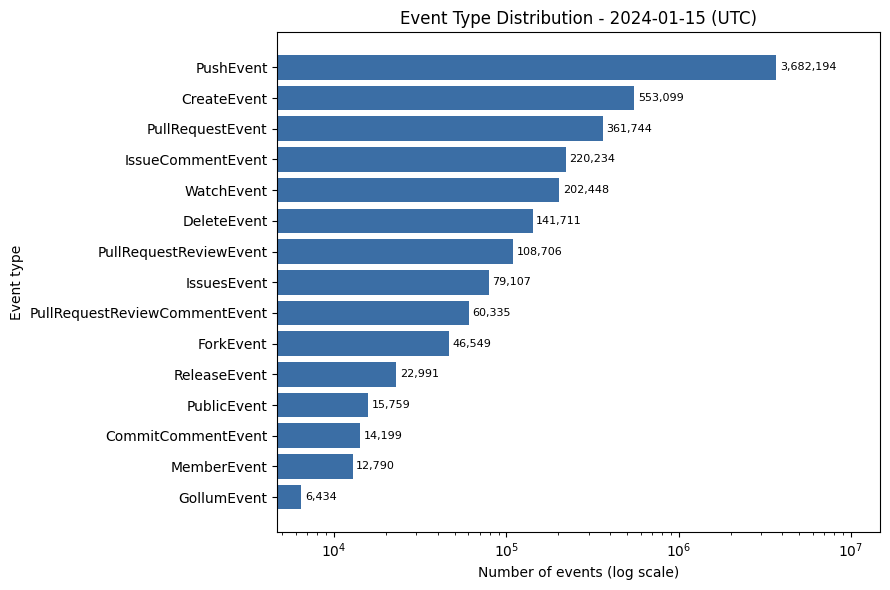

In [8]:
# Chart 1: event type distribution.
counts = type_counts["event_count"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(counts.index, counts.values, color="#3b6ea5")
ax.set_xscale("log")
ax.set_xlabel("Number of events (log scale)")
ax.set_ylabel("Event type")
ax.set_title("Event Type Distribution - 2024-01-15 (UTC)")
for bar, value in zip(bars, counts.values):
    ax.text(value * 1.05, bar.get_y() + bar.get_height() / 2,
            f"{value:,}", va="center", fontsize=8)
ax.set_xlim(right=counts.max() * 4)
fig.tight_layout()
fig.savefig(FIG_DIR / "event_type_distribution.png", dpi=150)
plt.show()

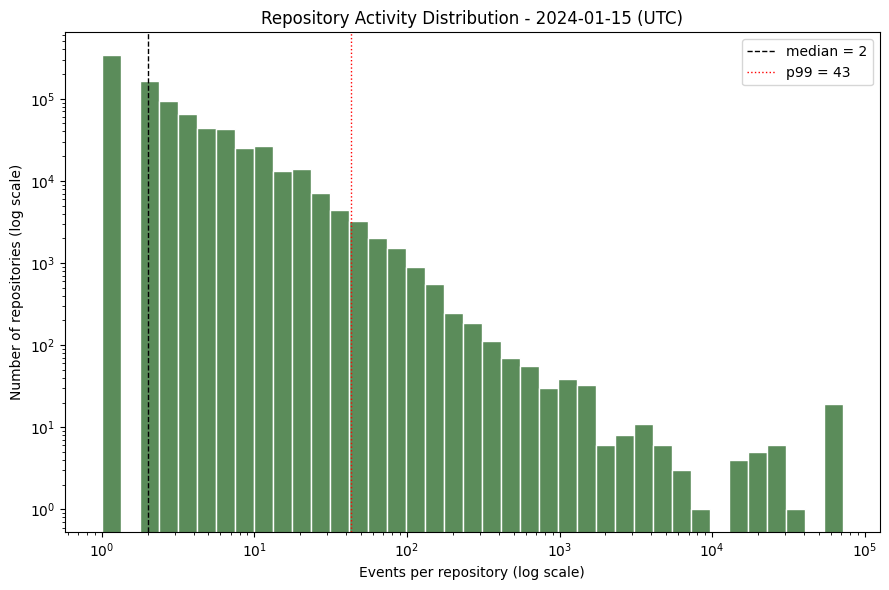

In [9]:
# Chart 2: repository activity distribution (events per repository).
fig, ax = plt.subplots(figsize=(9, 6))
bins = np.logspace(0, np.log10(repo_totals.max()) + 0.1, 40)
ax.hist(repo_totals.values, bins=bins, color="#5b8c5a", edgecolor="white")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Events per repository (log scale)")
ax.set_ylabel("Number of repositories (log scale)")
ax.set_title("Repository Activity Distribution - 2024-01-15 (UTC)")
median = repo_totals.median()
p99 = repo_totals.quantile(0.99)
ax.axvline(median, color="black", linestyle="--", linewidth=1, label=f"median = {median:g}")
ax.axvline(p99, color="red", linestyle=":", linewidth=1, label=f"p99 = {p99:g}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "repository_activity_distribution.png", dpi=150)
plt.show()

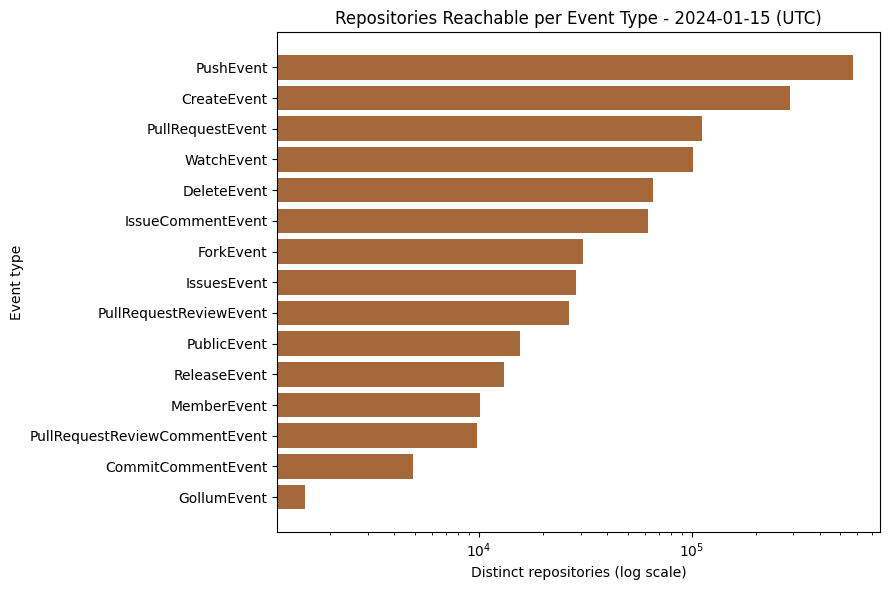

In [10]:
# Chart 3 (supplementary): breadth of each event type - how many repositories it touches.
breadth = type_counts["repo_count"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(breadth.index, breadth.values, color="#a5683b")
ax.set_xscale("log")
ax.set_xlabel("Distinct repositories (log scale)")
ax.set_ylabel("Event type")
ax.set_title("Repositories Reachable per Event Type - 2024-01-15 (UTC)")
fig.tight_layout()
fig.savefig(FIG_DIR / "event_type_repo_breadth.png", dpi=150)
plt.show()

### Reading the charts

Numbers below are computed from the 2024-01-15 full-day table (5,528,300 events, 852,777
repositories):

- **PushEvent dominates on both volume and reach.** It accounts for 3,682,194 events
  (66.6% of the day) and touches 570,500 repositories, the largest reach of any event type.
  The second most common type, CreateEvent, covers 288,146 repositories at 10.0% of events.
- **Repository activity is strongly skewed.** 340,631 repositories (39.9%) produced exactly
  one event in the day, and the median is 2 events per repository. A long tail of busy
  repositories pulls the mean well above the median, so a mean alone is misleading; use
  median and percentiles, and present activity on a log scale.
- These patterns describe a single UTC day (2024-01-15), not how repositories evolve over
  their lifetime. A longer window is needed for lifecycle conclusions.


## 7. Lifecycle metric definitions

Each metric is computed per repository. Two different units are kept apart on purpose: **event
counts** (how many activities) and **active days** (on how many distinct days an activity was
observed).

Issue and PR activity are split to avoid double counting and to keep issue comments separate:

- `IssuesEvent` counts issue open/close actions.
- `IssueCommentEvent` is reported on its own because a comment can land under a pull request
  as well as under an issue; lumping it with issues would inflate issue activity.
- PR activity groups the three PR-related event types.

| Metric | Unit | Definition | Source fields |
|---|---|---|---|
| `total_events` | events | sum of `event_count` for the repository | daily counts or event table |
| `push_events` | events | sum of `event_count` where `event_type == PushEvent` | |
| `issue_events` | events | sum of `IssuesEvent` only | |
| `issue_comment_events` | events | sum of `IssueCommentEvent` only | |
| `pr_events` | events | sum of `PullRequestEvent`, `PullRequestReviewEvent`, `PullRequestReviewCommentEvent` | |
| `active_days` | days | number of distinct `event_date` values with activity | daily counts `event_date` |

Notes and limits:

- The Issue/PR/Comment groupings are a **convention**. If the group decides a different split,
  change the type lists below and re-run. The choice must be stated in the report.
- One `PushEvent` is not one commit. A single push can carry several commits in its payload;
  counting commits would require the payload, which is not in the current event table.
- `active_days` needs a date column. On the current single-day table it is 1 for every
  repository. It only becomes informative once the observation window spans several days.


In [11]:
ISSUE_TYPES = ["IssuesEvent"]
ISSUE_COMMENT_TYPES = ["IssueCommentEvent"]
PR_TYPES = ["PullRequestEvent", "PullRequestReviewEvent", "PullRequestReviewCommentEvent"]


def repo_metrics(daily: pd.DataFrame) -> pd.DataFrame:
    """Compute per-repository activity metrics from a repo x date x type table.

    Expects columns: repo_id, event_date, event_type, event_count.
    """
    required = {"repo_id", "event_date", "event_type", "event_count"}
    missing = required - set(daily.columns)
    if missing:
        raise ValueError(f"missing columns: {sorted(missing)}")

    by_type = (
        daily.pivot_table(index="repo_id", columns="event_type",
                          values="event_count", aggfunc="sum", fill_value=0)
    )

    def sum_types(types):
        cols = [c for c in types if c in by_type.columns]
        return by_type[cols].sum(axis=1) if cols else 0

    metrics = pd.DataFrame(index=by_type.index)
    metrics["total_events"] = by_type.sum(axis=1)
    metrics["push_events"] = by_type.get("PushEvent", 0)
    metrics["issue_events"] = sum_types(ISSUE_TYPES)
    metrics["issue_comment_events"] = sum_types(ISSUE_COMMENT_TYPES)
    metrics["pr_events"] = sum_types(PR_TYPES)
    metrics["active_days"] = daily.groupby("repo_id")["event_date"].nunique()
    return metrics.sort_index()


repo_metrics_24h = repo_metrics(daily_24h)
print("repositories:", len(repo_metrics_24h))
repo_metrics_24h.head()


repositories: 852777


,total_events,push_events,issue_events,issue_comment_events,pr_events,active_days
repo_id,,,,,,
130,17,6,0,0,5,1
140,2,0,0,0,0,1
144,1,0,0,0,0,1
363,7,0,1,2,4,1
507,1,0,0,0,0,1


In [12]:
# Sanity check: the metrics reconcile with the raw table.
assert repo_metrics_24h["total_events"].sum() == daily_24h["event_count"].sum()
print("total_events sum matches daily table:", int(repo_metrics_24h["total_events"].sum()))
print("active_days value counts (full day has a single date):")
print(repo_metrics_24h["active_days"].value_counts())

total_events sum matches daily table: 5528300
active_days value counts (full day has a single date):
active_days
1    852777
Name: count, dtype: int64


## 8. Join with repository metadata (AI labels and creation time)

B owns the repository metadata and AI labels. The interface is a single key, `repo_id`. Both
tables are required to have one row per `repo_id`; if duplicate IDs are found the notebook
stops rather than silently dropping rows. The analysis reads `ai_label_final`; repositories
that do not appear in the labels table are recorded as "no label yet" and kept separate from
repositories whose final label is `uncertain`.

Two things to remember:

- `repo_created_at` from the API is the real repository creation time (used later for age
  months), while `first_observed_at` in `repo_candidates.csv` is only the first activity seen
  in the sample.
- `api_repo_id` must equal `repo_id` (and `fetch_status == "ok"`) before the metadata is used;
  otherwise the row is a renamed or different repository and its metadata is ignored.


In [13]:
# B interface: one row per repo_id in both metadata and labels. Duplicate IDs would silently
# drop rows during the merge, so we stop and report them instead of continuing.
def validate_one_per_repo(df: pd.DataFrame, name: str) -> None:
    dups = df.loc[df["repo_id"].duplicated(keep=False), "repo_id"].unique()
    if len(dups):
        raise ValueError(
            f"{name}: repo_id is not unique. {len(dups)} duplicate id(s): "
            f"{sorted(dups)[:10]}{'...' if len(dups) > 10 else ''}"
        )


validate_one_per_repo(metadata, "metadata")
validate_one_per_repo(labels, "labels")

# Only use metadata whose API id matches the event-table repo_id and whose fetch succeeded.
api_id = pd.to_numeric(metadata["api_repo_id"], errors="coerce").astype("Int64")
metadata_valid = metadata.loc[
    metadata["fetch_status"].eq("ok") & api_id.eq(metadata["repo_id"])
].copy()
metadata_valid["repo_created_at"] = pd.to_datetime(
    metadata_valid["repo_created_at"], utc=True, errors="coerce"
)
print(f"metadata rows kept for the join: {len(metadata_valid)} / {len(metadata)}")

# Analysis uses the final label (ai_label_final). Keep auto/manual columns for traceability.
label_cols = [c for c in ["repo_id", "ai_label_final", "ai_label_auto", "ai_label_manual",
                          "label_source", "rule_version", "policy"] if c in labels.columns]
labels_slim = labels[label_cols]

repo_level = (
    repo_metrics_24h.reset_index()
    .merge(metadata_valid[["repo_id", "repo_created_at", "current_full_name",
                           "language", "archived"]],
           on="repo_id", how="left")
    .merge(labels_slim, on="repo_id", how="left", validate="many_to_one")
)

# --- access summary -------------------------------------------------------
matched_repos = repo_level["ai_label_final"].notna().sum()
valid_creation = repo_level["repo_created_at"].notna().sum()
no_label = repo_level["ai_label_final"].isna().sum()

print(f"repositories in repo-level table : {len(repo_level)}")
print(f"matched to B labels              : {int(matched_repos)}")
print(f"  of which uncertain             : {int((repo_level['ai_label_final'] == 'uncertain').sum())}")
print(f"no label yet (unmatched)         : {int(no_label)}")
print(f"valid repo_created_at            : {int(valid_creation)}")
print()
print("ai_label_final distribution (matched repos only):")
print(repo_level["ai_label_final"].value_counts(dropna=False).to_string())


metadata rows kept for the join: 43 / 50


repositories in repo-level table : 852777
matched to B labels              : 50
  of which uncertain             : 8
no label yet (unmatched)         : 852727
valid repo_created_at            : 43

ai_label_final distribution (matched repos only):
ai_label_final
NaN          852727
excluded         38
uncertain         8
included          4


### Both pilot batches on the 24h table

To make sure the join works regardless of which batch is selected, the section below runs the
same validation on both `pilot_01` (50 repos) and `pilot_02` (200 repos) and prints a summary.
The expected reference values are: pilot_01 matches 50 repos with 43 valid creation times;
pilot_02 matches 200 repos with 163 valid creation times.


In [14]:
def pilot_access_summary(pilot: str, daily: pd.DataFrame) -> pd.Series:
    meta = pd.read_csv(B / "runs" / pilot / "repo_metadata.csv")
    lab = pd.read_csv(B / "runs" / pilot / "repo_ai_labels_analysis.csv")
    validate_one_per_repo(meta, f"{pilot} metadata")
    validate_one_per_repo(lab, f"{pilot} labels")
    api = pd.to_numeric(meta["api_repo_id"], errors="coerce").astype("Int64")
    valid = meta.loc[meta["fetch_status"].eq("ok") & api.eq(meta["repo_id"])].copy()
    valid["repo_created_at"] = pd.to_datetime(valid["repo_created_at"], utc=True, errors="coerce")
    in_daily = meta["repo_id"].isin(daily["repo_id"]).sum()
    joined = lab.merge(valid[["repo_id", "repo_created_at"]], on="repo_id", how="left")
    return pd.Series({
        "metadata_rows": len(meta),
        "label_rows": len(lab),
        "matched_in_daily": int(in_daily),
        "valid_creation": int(joined["repo_created_at"].notna().sum()),
        "included": int((joined["ai_label_final"] == "included").sum()),
        "excluded": int((joined["ai_label_final"] == "excluded").sum()),
        "uncertain": int((joined["ai_label_final"] == "uncertain").sum()),
        "rule_version": joined["rule_version"].iloc[0] if "rule_version" in joined else None,
        "policy": joined["policy"].iloc[0] if "policy" in joined else None,
    })


both = pd.DataFrame({
    p: pilot_access_summary(p, daily_24h) for p in ["pilot_01", "pilot_02"]
}).T
both.index.name = "pilot"
both


,metadata_rows,label_rows,matched_in_daily,valid_creation,included,excluded,uncertain,rule_version,policy
pilot,,,,,,,,,
pilot_01,50,50,50,43,4,38,8,ai_rules_v0.3.8,manual_override
pilot_02,200,200,200,163,17,87,96,ai_rules_v0.3.8,manual_override


### Age-month placeholder

Lifecycle month is defined from the repository's own creation time, not from the calendar month:

- `age_month = 1` for the calendar month in which the repository was created,
- `age_month = 2` for the following month, and so on.

The function below computes the calendar-month difference. It can only be applied once the event window
covers more than one month, and only for repositories whose whole first 12 months fall inside the
observation window. It is defined here so the monthly analysis can reuse it directly.

In [15]:
def age_month(created_at, event_date):
    """Calendar-month age of an activity, 1-based from the creation month.

    Returns a Series aligned with event_date. Values <= 0 mean the activity predates
    the creation month (should not happen) and must be reviewed.
    """
    created = pd.to_datetime(created_at, utc=True).dt.tz_localize(None)
    occurred = pd.to_datetime(event_date)
    return ((occurred.dt.year - created.dt.year) * 12
            + (occurred.dt.month - created.dt.month) + 1)


# Demonstration on the pilot rows only (a single day, so every value is far from month 1 here).
demo = repo_level[repo_level["repo_created_at"].notna()].copy()
demo["age_month_on_2024_01_15"] = age_month(
    demo["repo_created_at"],
    pd.Series("2024-01-15", index=demo.index),
)
demo[["repo_id", "repo_created_at", "age_month_on_2024_01_15"]].head()

,repo_id,repo_created_at,age_month_on_2024_01_15
33278,82206054,2017-02-16 17:15:47+00:00,84
47878,125461135,2018-03-16 03:57:24+00:00,71
108316,290350267,2020-08-25 23:59:48+00:00,42
113096,302309533,2020-10-08 10:48:31+00:00,40
114924,306977633,2020-10-24 21:49:40+00:00,40


## 9. What is ready and what is pending

Ready now:

- Event type and repository activity statistics and charts on the 2024-01-15 sample.
- A reusable per-repository metric function and lifecycle metric definitions.
- The `repo_id` join between event data and repository metadata, verified on the 50 pilot rows.

Pending (blocks the monthly lifecycle analysis):

1. **`repo_created_at` for the full candidate list** - from B. Without it, age months cannot be computed
   for more than 50 repositories.
2. **AI labels for the full candidate list**, plus the final label policy (`manual_override` vs `auto_only`,
   and how `uncertain` is counted) - from B.
3. **A longer event window** - from A. A single day cannot show a repository's first year; the age-month
   table and the activity curves need several months of data.

Next work items once the inputs arrive:

1. Build the `repo_id x age_month` activity table and the monthly metric columns.
2. Plot activity against age month, separately for AI and non-AI repositories.
3. Compare early activity with month-12 activity, and only then consider grouping repositories into patterns.

## 10. Weekly activity analysis (2024-01-15 to 2024-01-21)

This section uses the one-week data package delivered by A
(`C_一周分析数据包_20240115_20240121_20261111`). It is a separate, larger input from the
single-day table used above. The seven days are a fixed calendar observation window, **not**
each repository's first seven days. The goal here is to verify that the cross-day pipeline
works end to end; the 90-day age-band analysis follows later.

`PACKAGE` below points to where the package was extracted on this machine. Adjust it if the
package lives elsewhere. Large data files are not committed to the repo.


In [16]:
import json

# Adjust this path to the extracted package location on your machine.
PACKAGE = Path(r"e:\A_2026CityU\C5488\group work\_incoming_weekly\C_一周分析数据包_20240115_20240121_20261111")
assert PACKAGE.is_dir(), f"package not found: {PACKAGE}"

weekly = pd.read_parquet(PACKAGE / "data/a_weekly/repo_daily_counts.parquet")
weekly["event_date"] = pd.to_datetime(weekly["event_date"], utc=True)
coverage = json.loads((PACKAGE / "data/a_weekly/coverage.json").read_text(encoding="utf-8"))

print(f"rows           : {len(weekly):,}")
print(f"total events   : {int(weekly['event_count'].sum()):,}")
print(f"repos          : {weekly['repo_id'].nunique():,}")
print(f"date range     : {weekly['event_date'].min().date()} to {weekly['event_date'].max().date()}")
print(f"event types    : {weekly['event_type'].nunique()}")
print(f"verified hours : {coverage['verified_hours']} / {coverage['requested_hours']}")
print(f"missing hours  : {len(coverage['missing_source_hours'])}")

# Reference values from the package's validation.json.
assert len(weekly) == 8_636_288
assert int(weekly['event_count'].sum()) == 34_437_099
assert weekly['repo_id'].nunique() == 3_301_406
print("weekly table checks passed.")


rows           : 8,636,288
total events   : 34,437,099


repos          : 3,301,406
date range     : 2024-01-15 to 2024-01-21


event types    : 15
verified hours : 168 / 168
missing hours  : 0


weekly table checks passed.


### 10.1 Daily events and active repositories

For each UTC date we report the total event count and the number of distinct repositories
that had at least one event. Weekends show a clear drop in both volume and reach.


      date   weekday  events  active_repos
2024-01-15    Monday 5528300        852777
2024-01-16   Tuesday 5357213        877243
2024-01-17 Wednesday 5257142        880574
2024-01-18  Thursday 5091137        881644
2024-01-19    Friday 4954668        841807
2024-01-20  Saturday 4070829        669922
2024-01-21    Sunday 4177810        673663


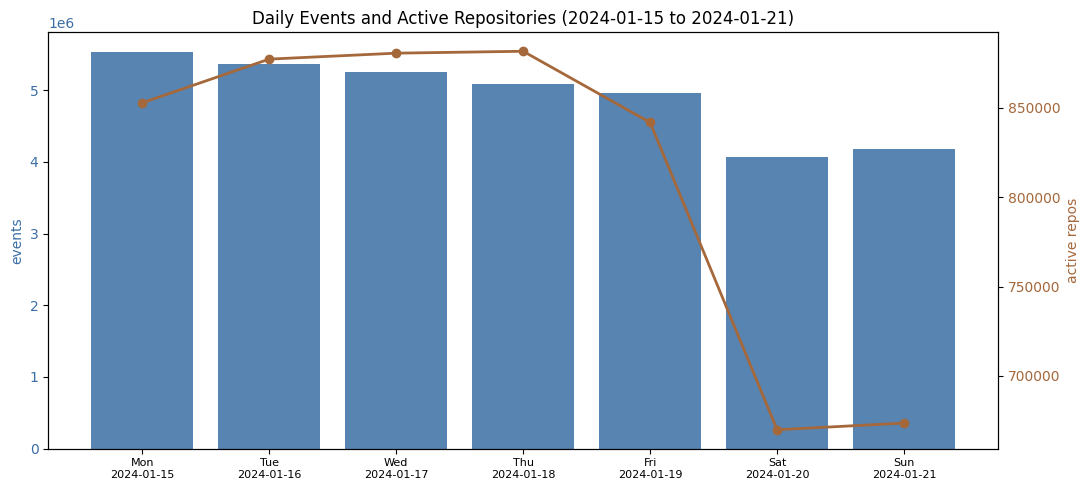

In [17]:
daily_totals = (
    weekly.groupby("event_date")
    .agg(events=("event_count", "sum"), active_repos=("repo_id", "nunique"))
    .reset_index()
)
daily_totals["weekday"] = daily_totals["event_date"].dt.day_name()
daily_totals["date"] = daily_totals["event_date"].dt.date
print(daily_totals[["date", "weekday", "events", "active_repos"]].to_string(index=False))

fig, ax1 = plt.subplots(figsize=(11, 5))
x = range(len(daily_totals))
bars = ax1.bar(x, daily_totals["events"], color="#3b6ea5", alpha=0.85, label="events")
ax1.set_ylabel("events", color="#3b6ea5")
ax1.tick_params(axis="y", labelcolor="#3b6ea5")
ax1.set_xticks(list(x))
ax1.set_xticklabels([f"{d.day_name()[:3]}\n{d.date()}" for d in daily_totals["event_date"]],
                    fontsize=8)
ax2 = ax1.twinx()
ax2.plot(x, daily_totals["active_repos"], color="#a5683b", marker="o", linewidth=2,
         label="active repos")
ax2.set_ylabel("active repos", color="#a5683b")
ax2.tick_params(axis="y", labelcolor="#a5683b")
ax1.set_title("Daily Events and Active Repositories (2024-01-15 to 2024-01-21)")
fig.tight_layout()
fig.savefig(FIG_DIR / "weekly_daily_events_repos.png", dpi=150)
plt.show()


### 10.2 Active days per repository

`active_days` is the number of distinct UTC dates on which a repository had at least one
event. Over seven fully-covered days, a value of 1 means the repository appeared on a single
day; 7 means it was active every day.


               repos   share
active_days                 
1            2287687  0.6929
2             473085  0.1433
3             202984  0.0615
4             111703  0.0338
5              72631  0.0220
6              48358  0.0146
7             104958  0.0318

mean active days: 1.72
median active days: 1


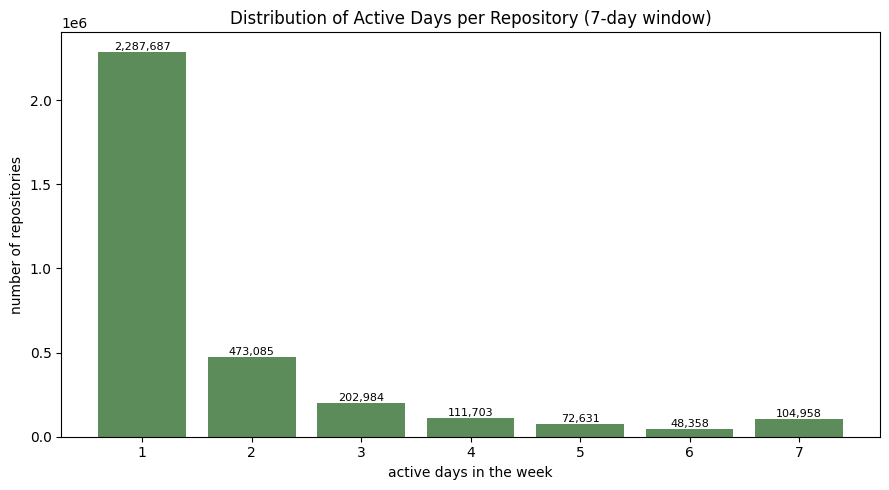

In [18]:
active_days = weekly.groupby("repo_id")["event_date"].nunique().rename("active_days")
ad_counts = active_days.value_counts().sort_index()
ad_share = (ad_counts / ad_counts.sum()).round(4)
ad_table = pd.DataFrame({"repos": ad_counts, "share": ad_share})
print(ad_table.to_string())
print(f"\nmean active days: {active_days.mean():.2f}")
print(f"median active days: {active_days.median():.0f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(ad_table.index, ad_table["repos"], color="#5b8c5a")
ax.set_xlabel("active days in the week")
ax.set_ylabel("number of repositories")
ax.set_title("Distribution of Active Days per Repository (7-day window)")
ax.set_xticks(range(1, 8))
for i, (d, n) in enumerate(zip(ad_table.index, ad_table["repos"])):
    ax.text(d, n, f"{n:,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "weekly_active_days_distribution.png", dpi=150)
plt.show()


### 10.3 AI-label pilot access (pilot_01, confirmed labels)

We use the **confirmed** pilot_01 labels from the package (rule version `ai_rules_v0.3.2`,
policy `manual_override`). pilot_02 final labels are not in this package and are not used for
label statistics here; only its metadata access is verified.

Repositories that do not appear in the labels table are recorded as **no label yet** and are
kept separate from repositories whose final label is `uncertain`.


In [19]:
wlab = pd.read_csv(PACKAGE / "data/b_pilot_01/repo_ai_labels_analysis.csv",
                   dtype={"repo_id": "int64"})
wmeta = pd.read_csv(PACKAGE / "data/b_pilot_01/repo_metadata.csv",
                    dtype={"repo_id": "int64", "api_repo_id": "string"})

validate_one_per_repo(wlab, "pilot_01 labels")
validate_one_per_repo(wmeta, "pilot_01 metadata")

api_id = pd.to_numeric(wmeta["api_repo_id"], errors="coerce").astype("Int64")
wmeta_ok = wmeta.loc[wmeta["fetch_status"].eq("ok") & api_id.eq(wmeta["repo_id"])].copy()
wmeta_ok["repo_created_at"] = pd.to_datetime(wmeta_ok["repo_created_at"], utc=True,
                                              errors="coerce")

# Join pilot_01 activity with labels and valid creation time.
pilot_weekly = (
    weekly.loc[weekly["repo_id"].isin(wlab["repo_id"])]
    .merge(wlab[["repo_id", "ai_label_final", "label_source", "rule_version"]],
           on="repo_id", how="left", validate="many_to_one")
    .merge(wmeta_ok[["repo_id", "repo_created_at"]], on="repo_id", how="left",
           validate="many_to_one")
)

matched = pilot_weekly["repo_id"].nunique()
valid_creation = pilot_weekly.loc[pilot_weekly["repo_created_at"].notna(), "repo_id"].nunique()
print(f"pilot_01 matched in weekly table : {matched} / {len(wlab)}")
print(f"valid repo_created_at           : {valid_creation} / {len(wlab)}")
print(f"pilot_01 total events this week : {int(pilot_weekly['event_count'].sum()):,}")
print(f"rule_version                    : {pilot_weekly['rule_version'].iloc[0]}")
print()
print("ai_label_final distribution (matched repos):")
print(wlab["ai_label_final"].value_counts(dropna=False).to_string())
print()
print("events by final label:")
print(pilot_weekly.groupby("ai_label_final")["event_count"].sum().to_string())


pilot_01 matched in weekly table : 50 / 50
valid repo_created_at           : 43 / 50
pilot_01 total events this week : 3,417
rule_version                    : ai_rules_v0.3.2

ai_label_final distribution (matched repos):
ai_label_final
excluded     38
uncertain     8
included      4

events by final label:
ai_label_final
excluded     3118
included       18
uncertain     281


#### Included repositories: weekly activity (small sample)

pilot_01 has only 4 `included` repositories, so the numbers below are a demonstration of the
pipeline, not a lifecycle conclusion. The sample size is stated explicitly.


included sample size: 4 repositories
included total events this week: 18

daily events per included repo:
repo_id     653701739  673960113  731867521  743310414
2024-01-15          5          5          2          5
2024-01-16          1          0          0          0


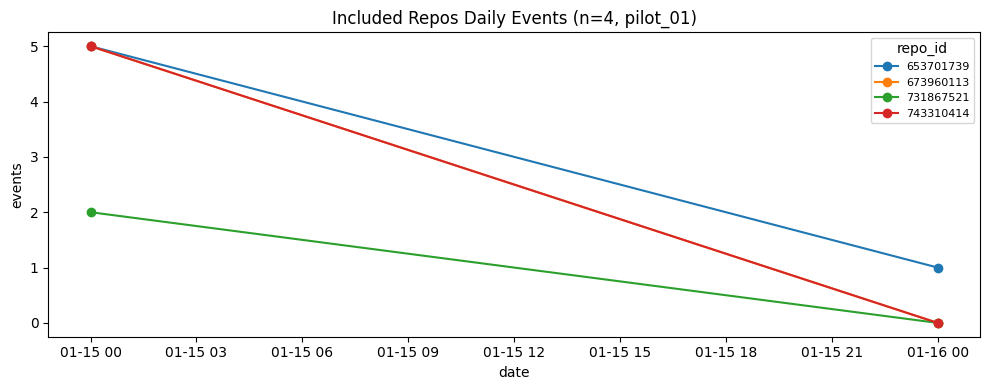

In [20]:
included_ids = wlab.loc[wlab["ai_label_final"] == "included", "repo_id"]
inc = pilot_weekly.loc[pilot_weekly["repo_id"].isin(included_ids)].copy()
print(f"included sample size: {inc['repo_id'].nunique()} repositories")
print(f"included total events this week: {int(inc['event_count'].sum())}")
print()
inc_daily = inc.groupby(["event_date", "repo_id"])["event_count"].sum().unstack(fill_value=0)
inc_daily.index = inc_daily.index.date
print("daily events per included repo:")
print(inc_daily.to_string())

if not inc_daily.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    inc_daily.plot(ax=ax, marker="o")
    ax.set_xlabel("date")
    ax.set_ylabel("events")
    ax.set_title(f"Included Repos Daily Events (n={inc['repo_id'].nunique()}, pilot_01)")
    ax.legend(title="repo_id", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "weekly_included_repos_daily.png", dpi=150)
    plt.show()


### 10.4 pilot_02 metadata access verification

pilot_02 final labels are **not delivered** in this package, so we only verify that its
metadata joins to the weekly table and that creation times are available. No final-label
statistics are produced for pilot_02.


In [21]:
wmeta2 = pd.read_csv(PACKAGE / "data/b_pilot_02/repo_metadata.csv",
                     dtype={"repo_id": "int64", "api_repo_id": "string"})
validate_one_per_repo(wmeta2, "pilot_02 metadata")

api2 = pd.to_numeric(wmeta2["api_repo_id"], errors="coerce").astype("Int64")
wmeta2_ok = wmeta2.loc[wmeta2["fetch_status"].eq("ok") & api2.eq(wmeta2["repo_id"])].copy()
wmeta2_ok["repo_created_at"] = pd.to_datetime(wmeta2_ok["repo_created_at"], utc=True,
                                               errors="coerce")

p2_in_weekly = wmeta2["repo_id"].isin(weekly["repo_id"]).sum()
p2_valid_creation = wmeta2_ok["repo_created_at"].notna().sum()
p2_events = int(weekly.loc[weekly["repo_id"].isin(wmeta2["repo_id"]), "event_count"].sum())
print(f"pilot_02 repos                  : {len(wmeta2)}")
print(f"matched in weekly table         : {p2_in_weekly}")
print(f"valid repo_created_at           : {p2_valid_creation}")
print(f"pilot_02 total events this week : {p2_events:,}")
print("pilot_02 final labels           : not delivered in this package")


pilot_02 repos                  : 200
matched in weekly table         : 200
valid repo_created_at           : 163
pilot_02 total events this week : 4,231
pilot_02 final labels           : not delivered in this package


### 10.5 Summary exports and access record

The daily totals, active-days distribution, and pilot access summaries are written to CSV so
they can be referenced without re-running the notebook. The package name, rule version and
environment are recorded here.


In [22]:
out = ROOT / "c_lifecycle_analysis" / "outputs"
out.mkdir(parents=True, exist_ok=True)

daily_totals[["date", "weekday", "events", "active_repos"]].to_csv(
    out / "weekly_daily_totals.csv", index=False)
ad_table.reset_index().rename(columns={"index": "active_days"}).to_csv(
    out / "weekly_active_days_distribution.csv", index=False)

access = pd.DataFrame([
    {"pilot": "pilot_01", "repos": len(wlab),
     "matched_in_weekly": int(matched), "valid_creation": int(valid_creation),
     "included": int((wlab["ai_label_final"] == "included").sum()),
     "excluded": int((wlab["ai_label_final"] == "excluded").sum()),
     "uncertain": int((wlab["ai_label_final"] == "uncertain").sum()),
     "final_labels": "delivered",
     "rule_version": wlab["rule_version"].iloc[0], "policy": wlab["policy"].iloc[0]},
    {"pilot": "pilot_02", "repos": len(wmeta2),
     "matched_in_weekly": int(p2_in_weekly), "valid_creation": int(p2_valid_creation),
     "included": None, "excluded": None, "uncertain": None,
     "final_labels": "not delivered", "rule_version": None, "policy": None},
])
access.to_csv(out / "weekly_pilot_access.csv", index=False)
print(access.to_string(index=False))
print()
print(f"package: {PACKAGE.name}")
print(f"pandas: {pd.__version__} | pyarrow: {__import__('pyarrow').__version__}")


   pilot  repos  matched_in_weekly  valid_creation  included  excluded  uncertain  final_labels    rule_version          policy
pilot_01     50                 50              43       4.0      38.0        8.0     delivered ai_rules_v0.3.2 manual_override
pilot_02    200                200             163       NaN       NaN        NaN not delivered             NaN             NaN

package: C_一周分析数据包_20240115_20240121_20261111
pandas: 3.0.2 | pyarrow: 26.0.1


### 10.6 Reading the weekly results

- **Daily volume tracks the weekday.** Events range from 4.07M (Saturday, 2024-01-20) to
  5.53M (Monday, 2024-01-15); active repositories range from 0.67M to 0.88M. Both metrics fall
  on the weekend and recover in the following week. This is expected for GitHub public activity.
- **Most repositories are active on a single day.** The active-days distribution is dominated
  by the 1-day bucket; only a small fraction of repositories appear on all seven days. This
  matches the single-day finding that many repositories produce very little activity.
- **pilot_01 label access is clean.** All 50 pilot_01 repositories match the weekly table, 43
  have a valid creation time, and the final-label split is 4 `included` / 38 `excluded` / 8
  `uncertain`. The 4 `included` repositories together produced 18 events over the week, too few
  for a lifecycle conclusion; the pipeline is verified but the sample is not.
- **pilot_02 is metadata-only in this package.** All 200 repositories match the weekly table
  and 163 have a valid creation time, but final labels are not delivered here, so no label
  statistics are produced for pilot_02.
- **No-label vs. uncertain are kept apart.** The 3,301,406 repositories in the weekly table
  that are not in pilot_01 are recorded as having no label yet, not as `uncertain`. Only the 8
  pilot_01 repositories whose final label is `uncertain` count as uncertain.
- **No data gaps in this week.** coverage.json reports 168/168 verified source hours with no missing hours, so every UTC date in 2024-01-15..2024-01-21 is fully covered. A repository with no events on a covered date is treated as 0 activity that day, not as unknown; there are no gap dates that need to be kept as missing.

## 11. Review of D's six-hour parallel experiments

D delivered three Spark configurations (L1 single-core, L4 four-core local, D4 two-worker)
each run three times on the same six-hour input (2024-01-15 UTC 0-5h, 1,177,282 cleaned
events). This section reads D's machine-readable summary and stability files from the repo
and re-computes the headline numbers so they are traceable from source files, not copied.

Source files:
- `d_parallel_experiments/results/completed_20261111/measurements/six_hour_comparison.json`
- `d_parallel_experiments/results/completed_20261111/measurements/six_hour_stability.json`


In [23]:
import json

D_MEAS = ROOT / "d_parallel_experiments/results/completed_20261111/measurements"
with open(D_MEAS / "six_hour_comparison.json", encoding="utf-8") as f:
    cmp = json.load(f)
with open(D_MEAS / "six_hour_stability.json", encoding="utf-8") as f:
    stab = json.load(f)

print(f"comparison passed: {cmp['passed']}")
print(f"comparison method: {cmp['comparison']}")
print(f"runs recorded     : {len(cmp['records'])}")

# Reconstruct the per-run table from the comparison records.
runs = pd.DataFrame(cmp["records"])[
    ["run_id", "mode", "elapsed_seconds", "exit_code", "events"]
]
runs = runs.sort_values(["mode", "run_id"]).reset_index(drop=True)
runs["elapsed_seconds"] = runs["elapsed_seconds"].round(3)
print(runs.to_string(index=False))


comparison passed: True
comparison method: full ordered CSV SHA-256 and unordered Parquet row fingerprints including multiplicity
runs recorded     : 9
         run_id mode  elapsed_seconds  exit_code  events
 d4stable_6h_r1   D4           91.566          0 1177282
 d4stable_6h_r2   D4          100.786          0 1177282
 d4stable_6h_r3   D4           90.577          0 1177282
       l1_6h_r1   L1          210.215          0 1177282
       l1_6h_r2   L1          207.113          0 1177282
l1_6h_r3_resume   L1          220.207          0 1177282
       l4_6h_r1   L4           85.570          0 1177282
       l4_6h_r2   L4           85.588          0 1177282
       l4_6h_r3   L4           85.849          0 1177282


### 11.1 Median, speedup and throughput

Speedup is relative to L1 (single core). Throughput uses the median elapsed time and the
fixed event count 1,177,282. These values are recomputed here from `cmp["summary"]`.


In [24]:
EVENTS = 1_177_282
summary = cmp["summary"]
rows = []
for mode in ["L1", "L4", "D4"]:
    s = summary[mode]
    rows.append({
        "mode": mode,
        "r1_s": round(s["raw_seconds"][0], 3),
        "r2_s": round(s["raw_seconds"][1], 3),
        "r3_s": round(s["raw_seconds"][2], 3),
        "median_s": round(s["median_seconds"], 3),
        "speedup_vs_L1": round(s["speedup_vs_L1"], 2),
        "events_per_s": round(EVENTS / s["median_seconds"], 0),
    })
perf = pd.DataFrame(rows)
print(perf.to_string(index=False))

# Sanity-check the speedup D reported.
assert abs(perf.loc[perf['mode'] == 'L4', 'speedup_vs_L1'].iloc[0] - 2.46) < 0.01
assert abs(perf.loc[perf['mode'] == 'D4', 'speedup_vs_L1'].iloc[0] - 2.30) < 0.01
print("\nspeedup values match the report (L4 2.46x, D4 2.30x).")


mode    r1_s    r2_s    r3_s  median_s  speedup_vs_L1  events_per_s
  L1 210.215 207.113 220.207   210.215           1.00        5600.0
  L4  85.570  85.588  85.849    85.588           2.46       13755.0
  D4  91.566 100.786  90.577    91.566           2.30       12857.0

speedup values match the report (L4 2.46x, D4 2.30x).


### 11.2 Stability

All nine runs completed with exit code 0, 577 successful tasks each, no task retries, no
stage failures, no executor removals, and no memory/disk spill. L4 is the most stable (CV
0.18%); D4 shows the largest spread (CV 5.97%, max/min 11.3%) without any failure signal.


In [25]:
var_rows = []
for mode in ["L1", "L4", "D4"]:
    v = stab["variability"][mode]
    var_rows.append({
        "mode": mode,
        "n": v["n"],
        "mean_s": round(v["mean_seconds"], 2),
        "sample_sd_s": round(v["sample_sd_seconds"], 2),
        "cv_percent": round(v["cv_percent"], 2),
        "max_over_min_percent": round(v["max_over_min_percent"], 2),
    })
var_df = pd.DataFrame(var_rows)
print(var_df.to_string(index=False))

# Verify zero failures across all nine runs.
stab_runs = pd.DataFrame(stab["runs"])
assert (stab_runs["task_attempt_gt_zero"] == 0).all()
assert (stab_runs["stage_failures"].str.len() == 0).all()
assert (stab_runs["executor_removals"].str.len() == 0).all()
assert (stab_runs["spill_bytes"] == 0).all()
print("\nAll 9 runs: 0 retries, 0 stage failures, 0 executor removals, 0 spill bytes.")


mode  n  mean_s  sample_sd_s  cv_percent  max_over_min_percent
  L1  3  212.51         6.84        3.22                  6.32
  L4  3   85.67         0.16        0.18                  0.33
  D4  3   94.31         5.63        5.97                 11.27

All 9 runs: 0 retries, 0 stage failures, 0 executor removals, 0 spill bytes.


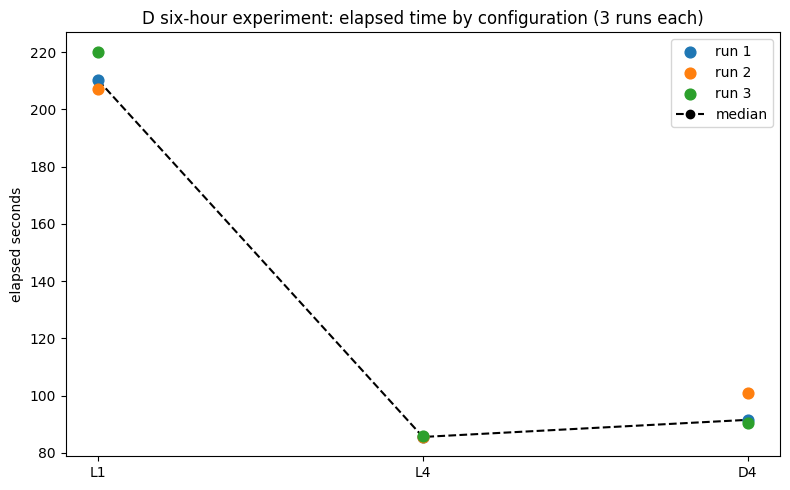

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
modes = perf["mode"].tolist()
x = range(len(modes))
raw = [summary[m]["raw_seconds"] for m in modes]
for i in range(3):
    ax.scatter(x, [r[i] for r in raw], s=60, label=f"run {i+1}", zorder=3)
ax.plot(x, perf["median_s"], "k--", marker="o", label="median", zorder=2)
ax.set_xticks(list(x))
ax.set_xticklabels(modes)
ax.set_ylabel("elapsed seconds")
ax.set_title("D six-hour experiment: elapsed time by configuration (3 runs each)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "d_six_hour_elapsed.png", dpi=150)
plt.show()


### 11.3 Interpretation and limits

- **L4 is fastest** at 85.6 s median (2.46x over L1); D4 is close at 91.6 s (2.30x). The
  two-worker setup does not beat local four-core on this machine, consistent with the report's
  note that all configs share one physical host and D4 pays extra driver/OS and shuffle cost.
- **Correctness is consistent**: all nine runs output 1,177,282 events and pass the full
  ordered-CSV SHA-256 and unordered-Parquet fingerprint comparison.
- **Stability is acceptable but not uniform**: L4 is very stable (CV 0.18%); D4 has visible
  run-to-run variation (CV 5.97%) without failures, likely from host-level contention rather
  than Spark errors.
- These results are for six hours of input on a single physical machine. They do not predict
  24-hour or multi-server scaling. D's 24-hour run and the Spark-vs-Python reconciliation are
  still pending.


## 12. 90-day age-band analysis (small-sample framework)

The plan is to compare repositories created in 2024-04 and 2026-04 over their first 90 days,
split into day 1-30, 31-60, and 61-90. The formal cohort is not available yet, so this section
builds the **framework** and runs it on a small sample: pilot repositories whose creation time
is within 90 days of the observation window.

Caveats specific to this sample:

- The observation window is only 2024-01-15 to 2024-01-21 (7 days), so the 31-60 and 61-90
  bands are empty by construction. The 1-30 band is partially covered.
- pilot repositories are not the formal 2024-04 / 2026-04 new-repo cohort; they are a
  convenience sample to prove the code path. The numbers below are not lifecycle conclusions.

When the formal cohort and 90-day activity data arrive, the same functions below run unchanged;
only the input paths and the year switch change.


In [27]:
def age_day_band(age_days):
    """Map an age in days to a 90-day band label. Age is 0-based (day 0 = creation day)."""
    if pd.isna(age_days):
        return None
    if age_days < 0:
        return "pre_creation"  # event before repo creation; should not happen
    if age_days <= 29:
        return "day_1_30"
    if age_days <= 59:
        return "day_31_60"
    if age_days <= 89:
        return "day_61_90"
    return "beyond_90"


def age_band_metrics(daily: pd.DataFrame, metadata: pd.DataFrame) -> pd.DataFrame:
    """Per-repository, per-band event counts and active days.

    daily: repo_id, event_date (utc datetime), event_type, event_count
    metadata: repo_id, repo_created_at (utc datetime), one row per repo
    Returns a long table: repo_id, band, total_events, active_days.
    """
    m = metadata[["repo_id", "repo_created_at"]].dropna(subset=["repo_created_at"])
    df = daily.merge(m, on="repo_id", how="inner")
    df["age_days"] = (df["event_date"] - df["repo_created_at"]).dt.days
    df["band"] = df["age_days"].map(age_day_band)
    g = df.groupby(["repo_id", "band"])
    out = g.agg(total_events=("event_count", "sum"),
                active_days=("event_date", "nunique")).reset_index()
    return out


In [28]:
# Build the small sample from pilot_01 + pilot_02 (valid creation times only).
p1_meta = pd.read_csv(PACKAGE / "data/b_pilot_01/repo_metadata.csv",
                      dtype={"repo_id": "int64", "api_repo_id": "string"})
p2_meta = pd.read_csv(PACKAGE / "data/b_pilot_02/repo_metadata.csv",
                      dtype={"repo_id": "int64", "api_repo_id": "string"})

def valid_meta(meta):
    api = pd.to_numeric(meta["api_repo_id"], errors="coerce").astype("Int64")
    ok = meta.loc[meta["fetch_status"].eq("ok") & api.eq(meta["repo_id"])].copy()
    ok["repo_created_at"] = pd.to_datetime(ok["repo_created_at"], utc=True, errors="coerce")
    return ok[["repo_id", "repo_created_at"]].dropna()

sample_meta = pd.concat([valid_meta(p1_meta), valid_meta(p2_meta)], ignore_index=True)
# Drop any duplicate repo_id across the two pilots.
sample_meta = sample_meta.drop_duplicates("repo_id", keep="first")
print(f"sample repos with valid creation time: {len(sample_meta)}")

# Restrict to repos whose age at 2024-01-15 is <= 90 days (so the 7-day window falls in 1-30).
ref = pd.Timestamp("2024-01-15", tz="UTC")
sample_meta["age_at_window_start"] = (ref - sample_meta["repo_created_at"]).dt.days
young = sample_meta[sample_meta["age_at_window_start"].between(0, 90)].copy()
print(f"repos with age 0-90 days at window start: {len(young)}")


sample repos with valid creation time: 206
repos with age 0-90 days at window start: 54


In [29]:
band_metrics = age_band_metrics(weekly, young)
print("band coverage (sample, 7-day window):")
print(band_metrics["band"].value_counts().reindex(
    ["day_1_30", "day_31_60", "day_61_90", "beyond_90", "pre_creation"], fill_value=0
).to_string())
print()
band_summary = (
    band_metrics.groupby("band")
    .agg(repos=("repo_id", "nunique"),
         total_events=("total_events", "sum"),
         mean_events_per_repo=("total_events", "mean"),
         mean_active_days=("active_days", "mean"))
    .round(2)
)
print(band_summary.to_string())


band coverage (sample, 7-day window):
band
day_1_30        36
day_31_60       12
day_61_90        9
beyond_90        1
pre_creation     0

           repos  total_events  mean_events_per_repo  mean_active_days
band                                                                  
beyond_90      1             5                  5.00              3.00
day_1_30      36           504                 14.00              2.64
day_31_60     12           119                  9.92              2.00
day_61_90      9            47                  5.22              1.78


### 12.1 Year switch and boundary check

`YEAR` below selects which cohort to analyze. The band boundaries are checked on the small
sample: a repository created exactly 30 days before an event should fall in `day_1_30` (day
29, 0-based), and one created 31 days before should fall in `day_31_60`.


In [30]:
YEAR = 2024  # switch to 2026 when the 2026-04 cohort is available
print(f"analysis year: {YEAR}")

# Boundary check on synthetic ages.
check_ages = [-1, 0, 29, 30, 59, 60, 89, 90]
print("boundary check:")
for a in check_ages:
    print(f"  age {a:>3} days -> {age_day_band(a)}")
assert age_day_band(29) == "day_1_30"
assert age_day_band(30) == "day_31_60"
assert age_day_band(59) == "day_31_60"
assert age_day_band(60) == "day_61_90"
assert age_day_band(89) == "day_61_90"
assert age_day_band(90) == "beyond_90"
print("\nboundary assertions passed.")


analysis year: 2024
boundary check:
  age  -1 days -> pre_creation
  age   0 days -> day_1_30
  age  29 days -> day_1_30
  age  30 days -> day_31_60
  age  59 days -> day_31_60
  age  60 days -> day_61_90
  age  89 days -> day_61_90
  age  90 days -> beyond_90

boundary assertions passed.


### 12.2 What this framework delivers and what is pending

- The `age_band_metrics` function produces, per repository and per 30-day band, the total
  event count and the number of active days. It is the same function that will run on the
  2024-04 and 2026-04 cohorts once their 90-day activity data are available.
- `YEAR` is the single switch between the two cohorts; all downstream code is year-agnostic.
- The boundary check confirms 1-30 / 31-60 / 61-90 are mutually exclusive and cover exactly
  days 0-89 (0-based).
- **Pending from A/B**: the formal 2024-04 and 2026-04 new-repo lists, and 90 days of activity
  for each. With those, the only change is pointing `daily` and `sample_meta` at the formal
  inputs and setting `YEAR`.
